In [315]:
import cPickle as pickle
import os

import numpy as np
import matplotlib.pyplot as plt
import quantities as pq
import scipy.sparse as sparse
from scipy.io import wavfile
from IPython.display import Audio, display

import soundsig
from soundsig.sound import spectrogram, plot_spectrogram

import config

from spikes.plotting import plot_spikes_with_timeseries
from spikes.plotting.segment_view import PlaybacksManager, SegmentViewer, TrialsViewer
from spikes.sorting.preprocess import collect_waveforms
from spikes.utils import bin_spikes

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
BIRD_NAME = "LbY6074"
BIRD = "LbY6074__161215_145633"

In [3]:
DATADIR = config.DATADIR
data_path = os.path.join(DATADIR, "birds", BIRD_NAME, BIRD, "spikes", "{}-sorted.pkl".format(BIRD))

In [4]:
with open(data_path, "rb") as datafile:
    block = pickle.load(datafile)
block.create_relationship(recursive=True, force=True, append=True)

In [5]:
align4 = [0, 7, 16, 80]
align3 = [1, 9, 11, 19, 21, 68, 69, 71, 73, 74, 82, 95, 97, 97, 98]
align2 = [2, 3, 4, 5, 8, 10, 12, 13, 17, 18, 20, 22, 67, 72, 85, 92, 93, 94, 99]

units_of_interest = [5, 11]

In [268]:
print len(align4), len(align3)

4 15


## Response to tutor song

Example tutor song shown

* Spikes convolved with gaussian with width std=0.4ms

* N=19 songs


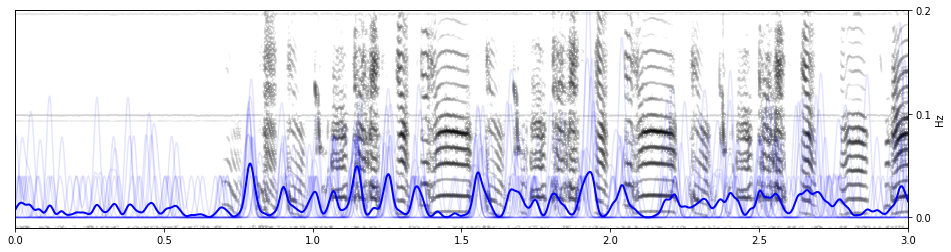

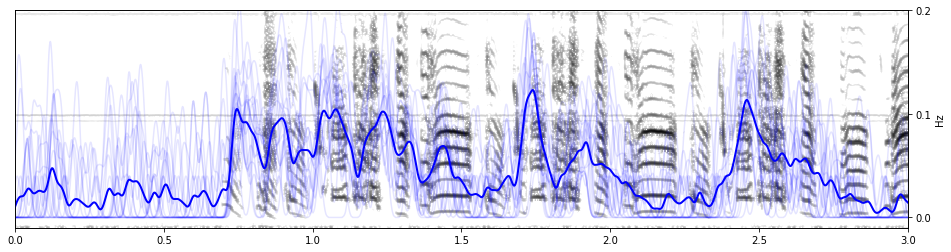

In [6]:
plt.clf()
trials_viewer = TrialsViewer(np.array(block.segments)[align3 + align4])
seg_viewer = trials_viewer.segment_viewers[0]

for fig_idx, unit in enumerate(units_of_interest):    
    fig, ax = plt.subplots(figsize=(16, 4))
    seg_viewer.plot_spectrogram(ax=ax, source=0, t_start=0)
    plt.ylabel("")
    plt.xlabel("")
    plt.yticks([])

    ax = ax.twinx()
    trials_viewer.plot_psth(unit, ax=ax, color="Blue", alpha=0.1, t_start=0)
    plt.yticks([0, 0.1, 0.2])
    plt.ylabel("Hz")
    plt.xlim(0, 3.0)
    plt.ylim(-.01, 0.2)

    # plt.tight_layout()
plt.show()

In [328]:
alignBOS = [14, 15, 23, 24, 26, 27,28,29,30,32, 34, 35, 36, 37, 38, 39, 41, 42, 43, 44, 45, 47, 48, 49, 55]
alignBOS = [14, 15, 23, 24, 26,28,29,30,32, 34, 35, 36, 37, 38, 39, 41, 42, 43, 44, 45, 47, 48, 49, 55]
print len(alignBOS)

24


In [329]:
# plt.clf()
# for i, seg in enumerate(np.array(block.segments)[alignBOS]):
#     if seg.annotations["sound_type"] == "playback":
#         continue
#     seg_viewer = SegmentViewer(seg)
#     trials_viewer = TrialsViewer([seg])
    
#     # TODO: view spectrogram of playback wav file too
#     plt.figure(figsize=(5, 1.5))
#     seg_viewer.plot_spectrogram(source=0)
#     plt.xlim(0.2, 1.4)
#     plt.ylabel("")
#     plt.xlabel("")
#     plt.yticks([])
#     plt.title(alignBOS[i])

# #     plt.tight_layout()
#     plt.show()

In [289]:
plt.clf()
#plot_spectrogram(t[t1:t2], f, basesig)
onset_times = []
for sid in alignBOS:
    bleh = np.mean(abs(SegmentViewer(block.segments[sid]).spectrogram(source=1)[2])**2, axis=0)
    for i, x in enumerate(bleh[440:1000]):
        if x > 1e-7:
            mmm = i
            break
    print sid, (440 + mmm)/1000.0
    onset_times.append((440 + mmm)/1000.0)
#     plt.figure()
#     plt.plot(bleh[440:1000])
#     plt.hlines([1e-7], 0, 400)
#     plt.vlines([mmm], 0, 1e-7)
#     plt.show()

14 0.679
15 0.696
23 0.693
24 0.694
26 0.665
27 0.534
28 0.568
29 0.668
30 0.691
32 0.683
34 0.672
35 0.65
36 0.68
37 0.682
38 0.682
39 0.674
41 0.68
42 0.655
43 0.656
44 0.66
45 0.68
47 0.676
48 0.678
49 0.691
55 0.669


## Response to BOS

Onsets aligned, lots of variability in syllable timing though

* Spikes convolved with gaussian with width std=0.4ms

* N=24 songs


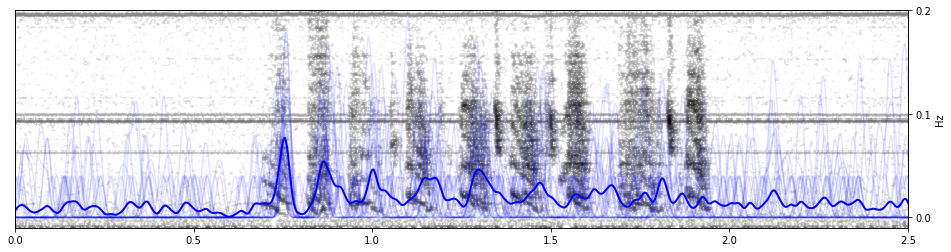

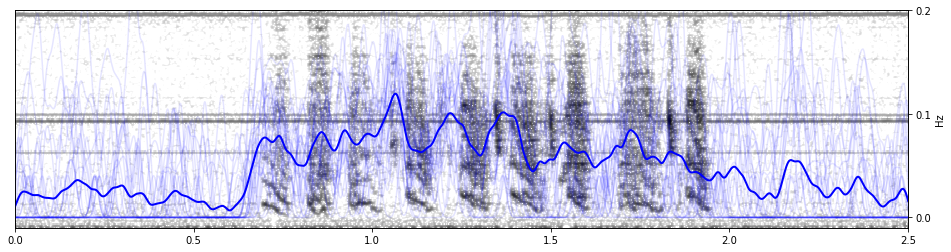

In [327]:
plt.clf()
trials_viewer = TrialsViewer(np.array(block.segments)[alignBOS], np.array(onset_times)-np.mean(onset_times))
seg_viewer = trials_viewer.segment_viewers[1]

for fig_idx, unit in enumerate(units_of_interest):    
    fig, ax = plt.subplots(figsize=(16, 4))
    seg_viewer.plot_spectrogram(ax=ax, source=1, t_start=0)
    plt.ylabel("")
    plt.xlabel("")
    plt.yticks([])

    ax = ax.twinx()
    trials_viewer.plot_psth(unit, ax=ax, color="Blue", alpha=0.1, t_start=0)
    plt.yticks([0, 0.1, 0.2])
    plt.ylabel("Hz")
    plt.xlim(0, 2.5)
    plt.ylim(-.01, 0.2)

    # plt.tight_layout()
plt.show()

## Comparison to unaligned

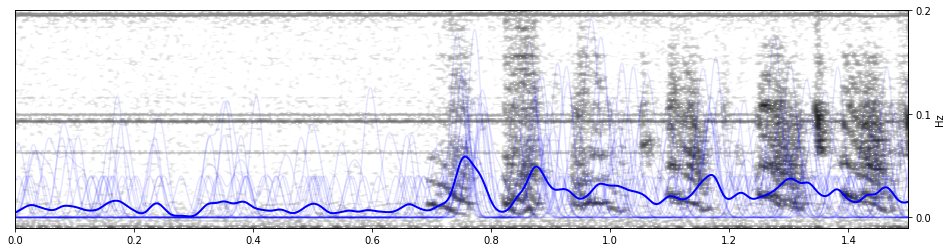

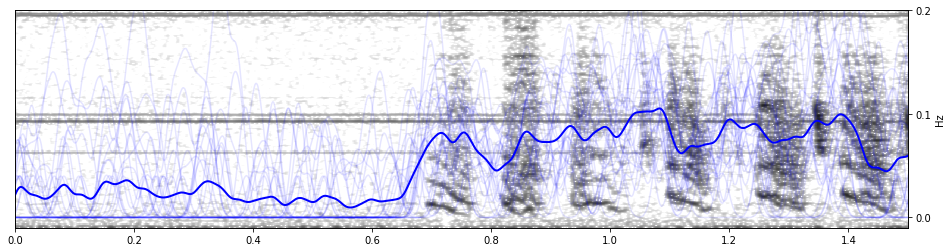

In [266]:
plt.clf()
trials_viewer = TrialsViewer(np.array(block.segments)[alignBOS])
seg_viewer = trials_viewer.segment_viewers[1]

for fig_idx, unit in enumerate(units_of_interest):    
    fig, ax = plt.subplots(figsize=(16, 4))
    seg_viewer.plot_spectrogram(ax=ax, source=1, t_start=0)
    plt.ylabel("")
    plt.xlabel("")
    plt.yticks([])

    ax = ax.twinx()
    trials_viewer.plot_psth(unit, ax=ax, color="Blue", alpha=0.1, t_start=0)
    plt.yticks([0, 0.1, 0.2])
    plt.ylabel("Hz")
    plt.xlim(0, 1.5)
    plt.ylim(-.01, 0.2)

    # plt.tight_layout()
plt.show()

# Crystallized Song Spectrogram

In [12]:
sr, crystallized_song = wavfile.read("/auto/fhome/kevin/Projects/songephys/data/birds/LbY6074/BOS/LBlYel923__January_06_2017_36897275.wav")

In [13]:
t_spec, f_spec, spec, rms = spectrogram(
        crystallized_song - np.mean(crystallized_song),
        sr,
        1000.0,
        50.0,
        min_freq=0,
        max_freq=10000,
        nstd=6)

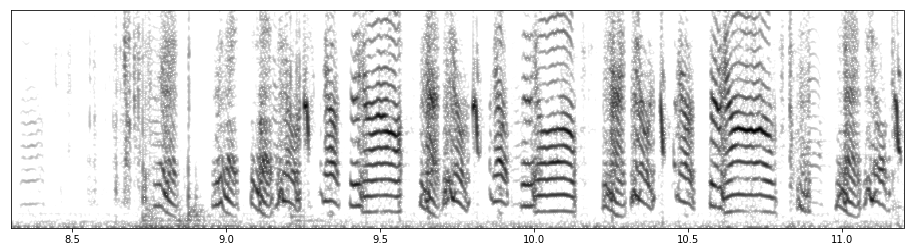

In [14]:
t_spec = t_spec - t_spec[0]

fig, ax = plt.subplots(figsize=(16, 4))
plot_spectrogram(t_spec, f_spec, spec, colormap="gray_r", ax=ax, colorbar=False)
plt.ylabel("")
plt.xlabel("")
plt.yticks([])

plt.xlim(8.3, 11.2)
plt.show()
